In [ ]:
using Fluidum
using PyPlot
#Plooting related imports
include("Libs/plotter.jl");
directory = "Plots/PbPb_502/";
save_plots = false;

In [46]:
const kernel_folder= "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Importance_Study/kernels_pce_502/";
PCE = true
# save_all_particles(kernel_folder; Tchem=145, Tkin=141, type = "thermal", PCE_bool = PCE)
# save_all_particles(kernel_folder_cuts; Tchem=145, Tkin=141, type = "total", PCE_bool = PCE)

# save_all_particles(kernel_folder; Tmin=110, Tmax=160, dT=10, type = "thermal")
# save_all_particles(kernel_folder; Tmin=110, Tmax=160, dT=10, type = "total")
dic = dictionary_lf(kernel_folder);

In [47]:
#define a radial grid
rmax = 40;
gridpoints=500;
grid_params = Fluidum.GridParameters(rmax, gridpoints);
disc=CartesianDiscretization(OriginInterval(gridpoints,rmax)) 

#decide the detector to use 
det = :ALICE;
det_name = detector_dict[det].name; 
dσ_QQdy = detector_dict[det].dσ_QQdy;
σ_in = detector_dict[det].σ_in;

tspan = (3.6, 30);
norm = 119.;
rdrop = 8.;
tau0 = tspan[1];

initial_params = Fluidum.InitialParameters(norm, tau0, rdrop);

#take the tabulated data 
ent = TabulatedData(string(@__DIR__, "/TabulatedData/EntropyProfile_", det_name, "502.txt"));

list = readresonancelist();

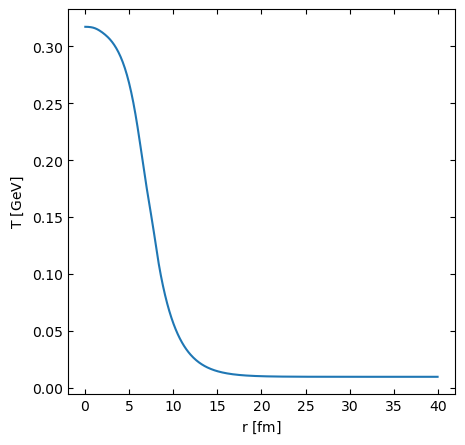

In [48]:
fields = Fluidum.initialize_fields(ent, 0, 5; grid_params, initial_params);
eos = FluiduMEoS();
#eos = Heavy_Quark();

plot_initial_field(fields; save=save_plots, path=directory*"initial_field_PCE_factor.png");

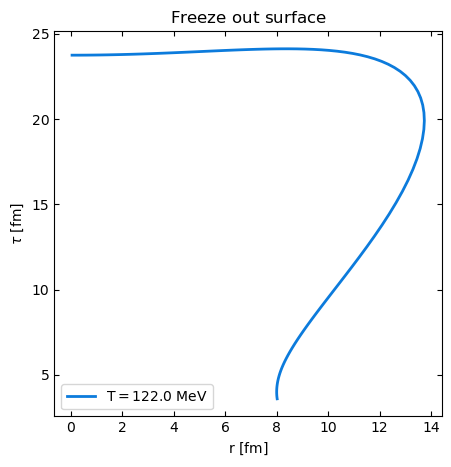

In [49]:
####################################zero diffusion
viscosity = QGPViscosity(0.1,0.2); #or, ZeroViscosity();
bulk = SimpleBulkViscosity(0.083,15.0); #or, ZeroBulkViscosity();

##########################no diffusion
diffusion = ZeroDiffusion();
params=Fluidum.FluidProperties(eos,viscosity,bulk,diffusion);
fo = freeze_out_routine(fields.discrete_field, Fluidum.matrxi1d_visc!, params, fields.initial_field, tspan; Tfo = 0.122);
plot_fo_surface(fo;save=save_plots);

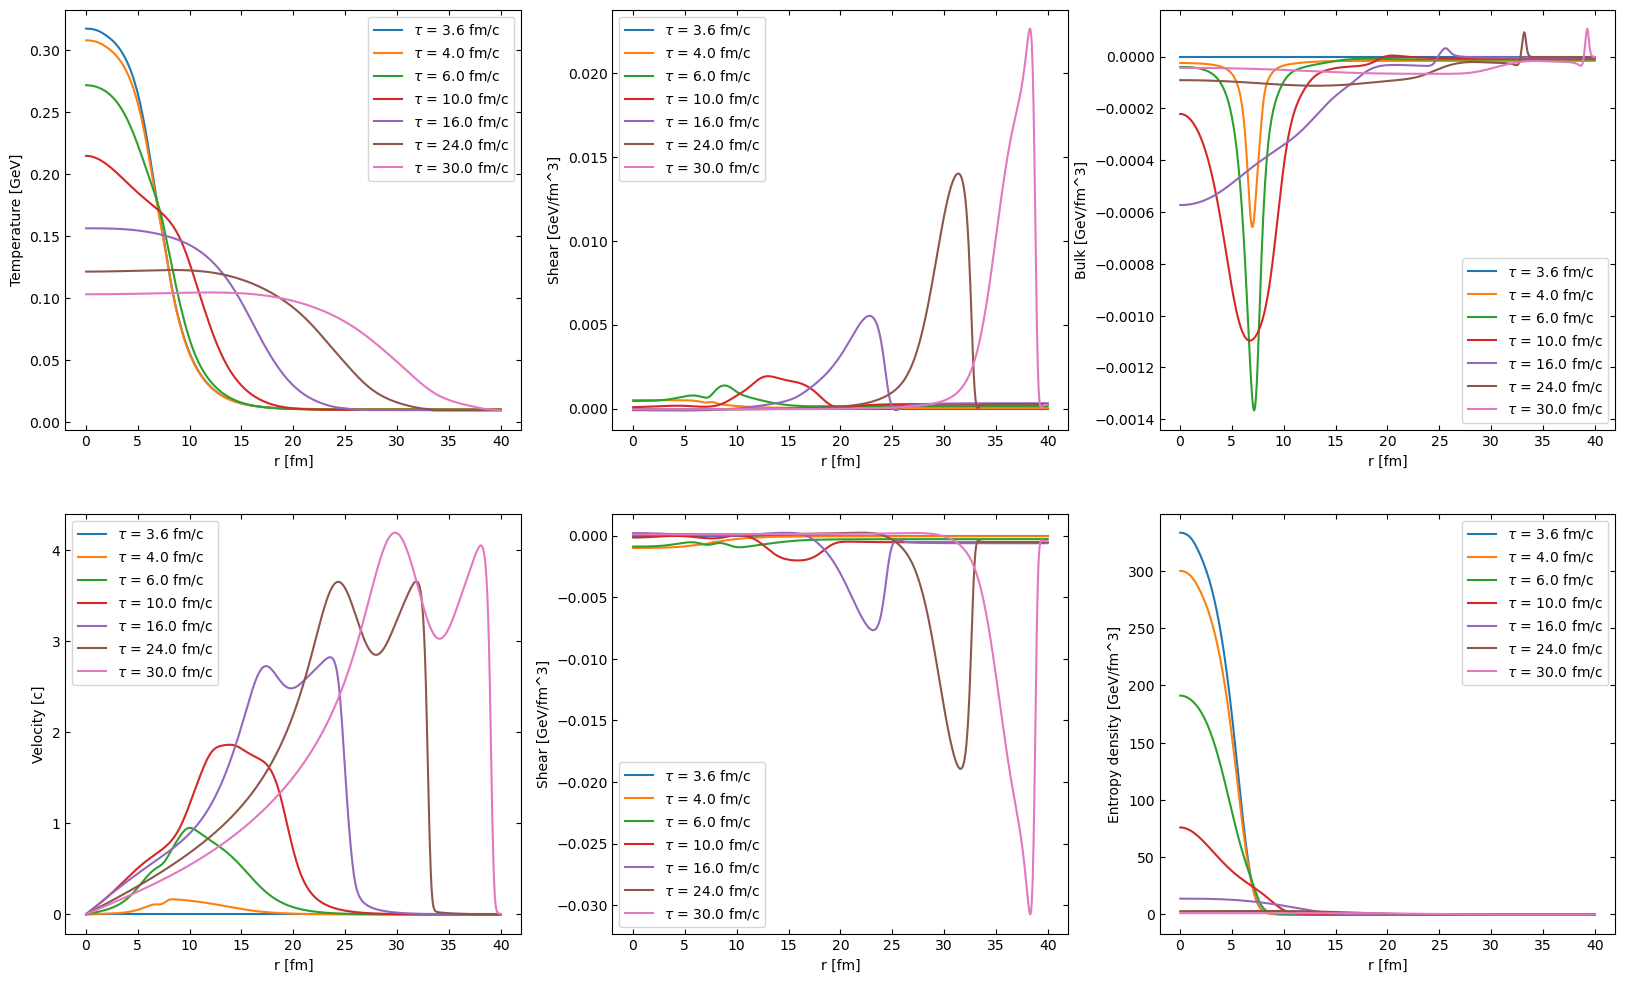

In [50]:
result_field = oneshoot(fields.discrete_field, Fluidum.matrxi1d_visc!, params, fields.initial_field, tspan; reltol = 1e-8);

times = [tspan[1], 4.0, 6.0, 10.0, 16.0, 24.0, tspan[2]]
radius = zeros(gridpoints+2)
[radius[i]= disc.grid[i][1] for i in eachindex(disc.grid[1:end])] 

plot_result_fields(result_field, radius, times, params; save=save_plots);

Here begins my own plotting routine

In [51]:
using CSV, DataFrames

function get_data(filename::String, endlines::Int=1)
    df = CSV.File(filename; comment = "#") |> DataFrame
    rename!(df,[:pt,:ptm,:ptp,:dNdpt,:statplus,:statmin,:systplus,:systmin,:systunplus,:systunmin])
    
    pt = parse.(Float64, first(df.pt, endlines))
    dNdpt = parse.(Float64, first(df.dNdpt, endlines))

    yerrp_stat=parse.(Float64, first(df.statplus, endlines))
    yerrm_stat=parse.(Float64, first(df.statmin, endlines))

    yerrp_syst=parse.(Float64, first(df.systplus, endlines))
    yerrm_syst=parse.(Float64, first(df.systmin, endlines))
    yerrp_un=parse.(Float64, first(df.systunplus, endlines))
    yerrm_un=parse.(Float64, first(df.systunmin, endlines))

    xerrm=pt.-parse.(Float64, first(df.ptm, endlines))

    return pt, dNdpt, yerrp_stat, yerrm_stat, yerrp_syst, yerrm_syst, yerrp_un, yerrm_un, xerrm
end


pt_Pion, dNdpt_Pion, yerrp_stat_Pion, yerrm_stat_Pion, yerrp_syst_Pion, yerrm_syst_Pion, yerrp_un_Pion, yerrm_un_Pion, xerrm_Pion = get_data("ExperimentalData/HEPData-ins1759506-v1-Table_1.csv", 36);
pt_Proton, dNdpt_Proton, yerrp_stat_Proton, yerrm_stat_Proton, yerrp_syst_Proton, yerrm_syst_Proton, yerrp_un_Proton, yerrm_un_Proton, xerrm_Proton = get_data("ExperimentalData/HEPData-ins1759506-v1-Table_5.csv", 29);
pt_Kaon, dNdpt_Kaon, yerrp_stat_Kaon, yerrm_stat_Kaon, yerrp_syst_Kaon, yerrm_syst_Kaon, yerrp_un_Kaon, yerrm_un_Kaon, xerrm_Kaon = get_data("ExperimentalData/HEPData-ins1759506-v1-Table_3.csv", 31);

mult_pion_data = (1699.80, 116.91);
mult_proton_data = (74.56, 3.75);
mult_kaon_data = (273.41, 11.62);


In [56]:
#@show dic.pion
use_3d_kernel = false;

spectrum_thermal_pion = spectra_lf(fo, dic.pion, params, pt_Pion; decays=false, interpolate_3d=use_3d_kernel);
spectrum_total_pion = spectra_lf(fo, dic.pion, params, pt_Pion; decays=true, interpolate_3d=use_3d_kernel);

spectrum_thermal_proton = spectra_lf(fo, dic.proton, params, pt_Proton; decays=false, interpolate_3d=use_3d_kernel);
spectrum_total_proton = spectra_lf(fo, dic.proton, params, pt_Proton; decays=true, interpolate_3d=use_3d_kernel);

spectrum_thermal_kaon = spectra_lf(fo, dic.kaon, params, pt_Kaon; decays=false, interpolate_3d=use_3d_kernel);
spectrum_total_kaon = spectra_lf(fo, dic.kaon, params, pt_Kaon; decays=true, interpolate_3d=use_3d_kernel);

mult_pion_thermal = multiplicity_lf(fo, dic.pion, params; decays=false,pt_min=0.002,pt_max=15.0, interpolate_3d=use_3d_kernel);
mult_pion_total = multiplicity_lf(fo, dic.pion, params; decays=true,pt_min=0.002,pt_max=15.0, interpolate_3d=use_3d_kernel);
mult_proton_thermal = multiplicity_lf(fo, dic.proton, params; decays=false,pt_min=0.002,pt_max=15.0, interpolate_3d=use_3d_kernel);
mult_proton_total = multiplicity_lf(fo, dic.proton, params; decays=true,pt_min=0.002,pt_max=15.0, interpolate_3d=use_3d_kernel);
mult_kaon_thermal = multiplicity_lf(fo, dic.kaon, params; decays=false,pt_min=0.002,pt_max=15.0, interpolate_3d=use_3d_kernel);
mult_kaon_total = multiplicity_lf(fo, dic.kaon, params; decays=true,pt_min=0.002,pt_max=15.0, interpolate_3d=use_3d_kernel);

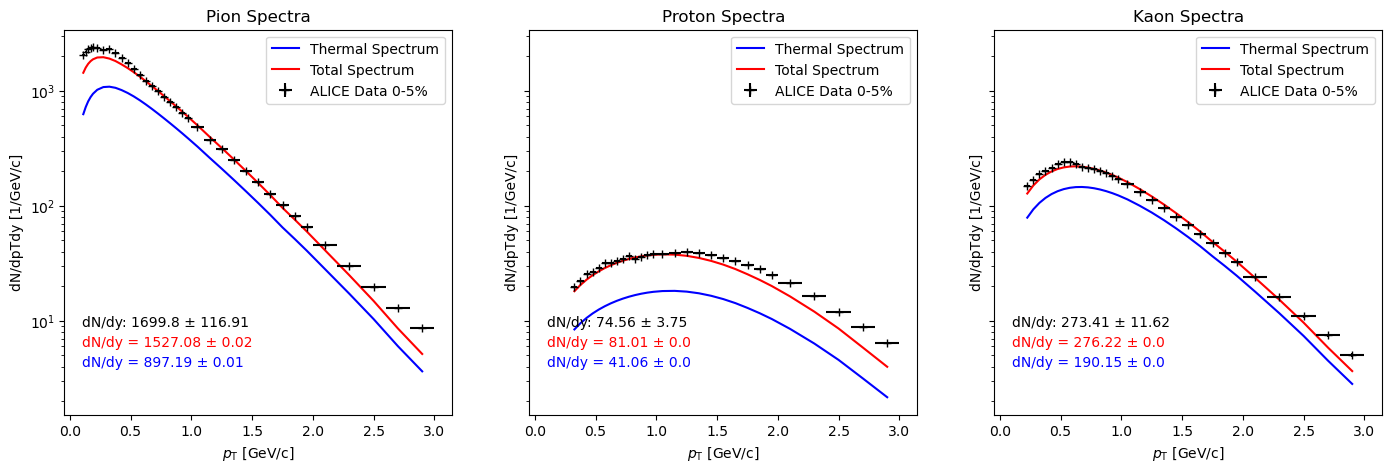

In [58]:
fig, ax = subplots(1,3, figsize=(17,5), sharey=true, sharex=true);
digits_print = 2;

ax[1].plot(pt_Pion, factor*2π *pt_Pion.*getindex.(spectrum_thermal_pion[:],1), label="Thermal Spectrum", color="blue")
ax[1].plot(pt_Pion, factor*2π *pt_Pion.*getindex.(spectrum_total_pion[:],1), label="Total Spectrum", color="red")
ax[1].errorbar(pt_Pion, dNdpt_Pion, yerr=(-yerrm_stat_Pion,yerrp_stat_Pion), xerr=xerrm_Pion, fmt="+", label="ALICE Data 0-5%", color="black")
ax[1].text(0.1, 6, "dN/dy = $(round(mult_pion_total[1], digits=digits_print)) ± $(round(mult_pion_total[2], digits=digits_print))", fontsize=10, color="red")
ax[1].text(0.1, 4, "dN/dy = $(round(mult_pion_thermal[1], digits=digits_print)) ± $(round(mult_pion_thermal[2], digits=digits_print))", fontsize=10, color="blue")
ax[1].text(0.1, 9, "dN/dy: $(round(mult_pion_data[1], digits=digits_print)) ± $(round(mult_pion_data[2], digits=digits_print))", fontsize=10, color="black")
ax[1].set_title("Pion Spectra")

ax[2].plot(pt_Proton, factor*2π *pt_Proton.*getindex.(spectrum_thermal_proton[:],1), label="Thermal Spectrum", color="blue")
ax[2].plot(pt_Proton, factor*2π *pt_Proton.*getindex.(spectrum_total_proton[:],1), label="Total Spectrum", color="red")
ax[2].errorbar(pt_Proton, dNdpt_Proton, yerr=(-yerrm_stat_Proton,yerrp_stat_Proton), xerr=xerrm_Proton, fmt="+", label="ALICE Data 0-5%", color="black")
ax[2].text(0.1, 6, "dN/dy = $(round(mult_proton_total[1], digits=digits_print)) ± $(round(mult_proton_total[2], digits=digits_print))", fontsize=10, color="red")
ax[2].text(0.1, 4, "dN/dy = $(round(mult_proton_thermal[1], digits=digits_print)) ± $(round(mult_proton_thermal[2], digits=digits_print))", fontsize=10, color="blue")
ax[2].text(0.1, 9, "dN/dy: $(round(mult_proton_data[1], digits=digits_print)) ± $(round(mult_proton_data[2], digits=digits_print))", fontsize=10, color="black")
ax[2].set_title("Proton Spectra")

ax[3].plot(pt_Kaon, factor*2π *pt_Kaon.*getindex.(spectrum_thermal_kaon[:],1), label="Thermal Spectrum", color="blue")
ax[3].plot(pt_Kaon, factor*2π *pt_Kaon.*getindex.(spectrum_total_kaon[:],1), label="Total Spectrum", color="red")
ax[3].errorbar(pt_Kaon, dNdpt_Kaon, yerr=(-yerrm_stat_Kaon,yerrp_stat_Kaon), xerr=xerrm_Kaon, fmt="+", label="ALICE Data 0-5%", color="black")
ax[3].text(0.1, 6, "dN/dy = $(round(mult_kaon_total[1], digits=digits_print)) ± $(round(mult_kaon_total[2], digits=digits_print))", fontsize=10, color="red")
ax[3].text(0.1, 4, "dN/dy = $(round(mult_kaon_thermal[1], digits=digits_print)) ± $(round(mult_kaon_thermal[2], digits=digits_print))", fontsize=10, color="blue")
ax[3].text(0.1, 9, "dN/dy: $(round(mult_kaon_data[1], digits=digits_print)) ± $(round(mult_kaon_data[2], digits=digits_print))", fontsize=10, color="black")
ax[3].set_title("Kaon Spectra")

for i in 1:3
    ax[i].set_yscale("log")
    ax[i].set_xlabel(L"$p_\mathrm{T}$ [GeV/c]")
    ax[i].set_ylabel("dN/dpTdy [1/GeV/c]")
    ax[i].legend()
end

if save_plots
    fig.savefig(directory*"spectra_PCE_factor.png", dpi=300)
end

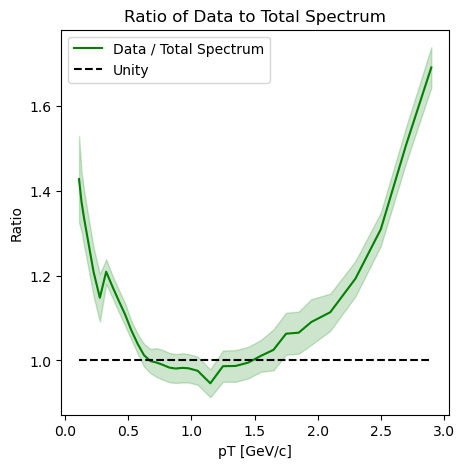

PyObject <matplotlib.legend.Legend object at 0x77d526648830>

In [54]:
ratio = dNdpt_Pion ./ (factor * 2π *pt_Pion.*getindex.(spectrum_total_pion[:],1))
yerrp_ratio = (yerrp_stat_Pion.^2 .+ yerrp_syst_Pion.^2).^0.5 ./ (factor * 2π *pt_Pion.*getindex.(spectrum_total_pion[:],1))
yerrm_ratio = (yerrm_stat_Pion.^2 .+ yerrm_syst_Pion.^2).^0.5 ./ (factor * 2π *pt_Pion.*getindex.(spectrum_total_pion[:],1))
fig2, ax2 = subplots(1,1, figsize=(5,5))
ax2.plot(pt_Pion, ratio, label="Data / Total Spectrum", color="green")
#ax2.plot(pt, ratio .+ yerrp_ratio, linestyle="--", color="green", label="Data + Total. Uncertainty")
#ax2.plot(pt, ratio .- yerrm_ratio, linestyle="--", color="green", label="Data - Total. Uncertainty")
ax2.fill_between(pt_Pion, ratio .+ yerrp_ratio, ratio .- yerrm_ratio, color="green", alpha=0.2)
ax2.plot(pt_Pion,[1 for i in pt_Pion], linestyle="--", color="black", label="Unity")
ax2.set_xlabel("pT [GeV/c]")
ax2.set_ylabel("Ratio")
ax2.set_title("Ratio of Data to Total Spectrum")
ax2.legend()

In [55]:
println(pt_Pion[1:31])
println(length(pt_Pion[1:11]))
yield_data = sum(dNdpt_Pion[1:11]) #integrate over the data points
yield_thermal = sum((factor * 2π *pt_Pion.*getindex.(spectrum_thermal_pion[:],1))[1:11]) #integrate over the thermal spectrum
yield_total = sum((factor * 2π *pt_Pion.*getindex.(spectrum_total_pion[:],1))[1:11]) #integrate over the total spectrum
println("Yield Data: ", round(yield_data))
println("Yield Thermal: ", round(yield_thermal))
println("Yield Total: ", round(yield_total))

norm_yield_data = sum(dNdpt_Pion[1:31])
println("Norm Yield Data: ", round(norm_yield_data))
excess = (yield_data - yield_total) / norm_yield_data
println("Excess in percentages: ", round(excess*100, digits=2), "%")

[0.11, 0.13, 0.15000000000000002, 0.16999999999999998, 0.19, 0.225, 0.275, 0.32499999999999996, 0.375, 0.42500000000000004, 0.475, 0.525, 0.575, 0.625, 0.675, 0.725, 0.775, 0.825, 0.875, 0.925, 0.975, 1.05, 1.15, 1.25, 1.35, 1.45, 1.55, 1.65, 1.75, 1.85, 1.95]
11
Yield Data: 24002.0
Yield Thermal: 10205.0
Yield Total: 19345.0
Norm Yield Data: 36053.0
Excess in percentages: 12.91%
